In [2]:
from pathlib import Path
from google.colab import files
import hashlib
import os
import zipfile

archive_path = Path('/content/resshift_dev_bundle.zip')
payload = archive_path.read_bytes()

root = Path('/content/resshift_dev')
root.mkdir(exist_ok=True)

with zipfile.ZipFile(archive_path) as archive:
    archive.extractall(root)

os.chdir(root)

In [3]:
import sys
import subprocess
from importlib.metadata import version

constraints = root / 'constraints.txt'
constraints.write_text(f"torch=={version('torch')}\ntorchvision=={version('torchvision')}\n")
packages = [
    'numpy', 'Pillow', 'pandas', 'requests', 'certifi', 'tqdm', 'matplotlib',
    'opencv-python-headless', 'lpips==0.1.4', 'omegaconf==2.3.0',
    'einops', 'timm', 'PyYAML', 'scipy', 'addict', 'future', 'loralib==0.1.2'
]
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                '-c', str(constraints), *packages], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', '-c', '/content/resshift_dev/constraints.txt', 'numpy', 'Pillow', 'pandas', 'requests', 'certifi', 'tqdm', 'matplotlib', 'opencv-python-headless', 'lpips==0.1.4', 'omegaconf==2.3.0', 'einops', 'timm', 'PyYAML', 'scipy', 'addict', 'future', 'loralib==0.1.2'], returncode=0)

In [4]:
import json
import random
import shutil
import time
import zlib
import numpy as np
import pandas as pd
import torch
import lpips
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
device = torch.device('cuda')
print(torch.cuda.get_device_name(0), torch.__version__)

for folder in ['datasets', 'models', 'evaluation']:
    sys.path.insert(0, str(root / 'code' / folder))
from resshift import ResShift
from download_data import download_file, WEIGHTS
import evaluate

Tesla T4 2.11.0+cu130


In [5]:
data = root / 'data/processed'
manifest = pd.read_csv(data / 'manifest.csv')
images = manifest[manifest['split'] == 'dev']
image_ids = images['image_id'].tolist()
qualities = ['none', '50', '30', '10']
image_seeds = {name: zlib.crc32(name.encode('utf-8')) & 0x7fffffff for name in image_ids}

results = root / 'run_artifacts'
results.mkdir(exist_ok=True)
outputs = results / 'outputs/dev/resshift'
provenance = json.loads((root / 'bundle_manifest.json').read_text())
images.groupby('content').size()

,0
content,
faces,20
objects,20
text,24


In [6]:
repo = root / 'third_party/ResShift'
revision = provenance['official_commit']
if not (repo / '.git').exists():
    repo.mkdir(parents=True, exist_ok=True)
    subprocess.run(['git', 'init', str(repo)], check=True)
    subprocess.run(['git', '-C', str(repo), 'remote', 'add', 'origin',
                    'https://github.com/zsyOAOA/ResShift.git'], check=True)
subprocess.run(['git', '-C', str(repo), 'fetch', '--depth', '1', 'origin', revision], check=True)
subprocess.run(['git', '-C', str(repo), 'checkout', '--detach', revision], check=True)

weights = ['resshift_realsrx4_s4_v3.pth', 'autoencoder_vq_f4.pth']
for name in weights:
    download_file(WEIGHTS[name], root / 'models' / name)
model = ResShift(device, root / 'models', version='v3', amp=True, seed=seed)

resshift_realsrx4_s4_v3.pth: 100%|██████████| 478M/478M [00:05<00:00, 91.9MB/s]
autoencoder_vq_f4.pth: 100%|██████████| 221M/221M [00:02<00:00, 95.7MB/s]


No module 'xformers'. Proceeding without it.


/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.13/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Working with z of shape (1, 3, 64, 64) = 12288 dimensions.


In [7]:
warmup = np.asarray(Image.open(data / 'lr/jpeg_none' / f'{image_ids[0]}.png').convert('RGB'))
for _ in range(3):
    model.upscale(warmup, seed=image_seeds[image_ids[0]])

timing = []
for quality in qualities:
    output_dir = outputs / f'jpeg_{quality}'
    output_dir.mkdir(parents=True, exist_ok=True)
    for image_id in tqdm(image_ids, desc=f'JPEG {quality}'):
        lr = np.asarray(Image.open(data / 'lr' / f'jpeg_{quality}' / f'{image_id}.png').convert('RGB'))
        torch.cuda.synchronize()
        start = time.perf_counter()
        sr = model.upscale(lr, seed=image_seeds[image_id])
        torch.cuda.synchronize()
        timing.append({'image_id': image_id, 'jpeg': quality,
                       'seconds': time.perf_counter() - start})
        Image.fromarray(sr).save(output_dir / f'{image_id}.png')

timing = pd.DataFrame(timing)
timing.to_csv(results / 'timing_resshift_dev.csv', index=False)
print(f"Mean inference time: {timing['seconds'].mean():.3f} s/image")
del model
torch.cuda.empty_cache()

/content/resshift_dev/code/models/resshift.py:98: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  y = torch.from_numpy(np.ascontiguousarray(lr)).permute(2, 0, 1)[None]


JPEG none:   0%|          | 0/64 [00:00<?, ?it/s]

JPEG 50:   0%|          | 0/64 [00:00<?, ?it/s]

JPEG 30:   0%|          | 0/64 [00:00<?, ?it/s]

JPEG 10:   0%|          | 0/64 [00:00<?, ?it/s]

Mean inference time: 0.909 s/image


In [8]:
lpips_model = lpips.LPIPS(net='alex', verbose=False).eval().to(device)
evaluate.OUTPUTS_DIR = results / 'outputs'
evaluate.METHODS = ['resshift']
metrics = evaluate.evaluate_split('dev', manifest, lpips_model, device)
summary = evaluate.summarize(metrics, seed)
metrics.to_csv(results / 'metrics_resshift_dev.csv', index=False)
summary.to_csv(results / 'summary_resshift_dev.csv', index=False)
summary.round(4)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 166MB/s]
resshift jpeg_10: 100%|██████████| 64/64 [00:06<00:00, 10.09it/s]


,content,jpeg,method,images,psnr,psnr_ci,ssim,ssim_ci,lpips,lpips_ci
0,objects,none,resshift,20,25.4699,1.6201,0.7006,0.0507,0.2121,0.0295
1,faces,none,resshift,20,32.2563,0.6681,0.8616,0.0177,0.1079,0.0099
2,text,none,resshift,24,19.7583,1.6669,0.8581,0.0475,0.0852,0.0192
3,objects,50,resshift,20,23.8209,1.4144,0.6047,0.0557,0.3189,0.0323
4,faces,50,resshift,20,30.3071,0.6029,0.8088,0.0214,0.2020,0.0167
5,text,50,resshift,24,18.0409,1.3812,0.8055,0.0549,0.1101,0.0197
6,objects,30,resshift,20,23.3788,1.3609,0.5787,0.0560,0.3491,0.0300
7,faces,30,resshift,20,29.6518,0.6112,0.7930,0.0231,0.2273,0.0187
8,text,30,resshift,24,17.0542,1.1742,0.7733,0.0559,0.1312,0.0209
9,objects,10,resshift,20,22.2623,1.2167,0.5282,0.0545,0.4559,0.0270


In [9]:
baseline = pd.read_csv(root / 'baseline/metrics_dev.csv', dtype={'jpeg': str})
baseline_summary = pd.read_csv(root / 'baseline/summary_dev.csv', dtype={'jpeg': str})
baseline_paired = pd.read_csv(root / 'baseline/paired_dev.csv', dtype={'jpeg': str})
combined = pd.concat([baseline, metrics], ignore_index=True)
all_summary = pd.concat([baseline_summary, summary], ignore_index=True)
paired = pd.concat([
    evaluate.compare_methods(combined, method, 'resshift', seed)
    for method in ['bicubic', 'realesrnet', 'realesrgan']
], ignore_index=True)

combined_dir = results / 'combined'
combined_dir.mkdir(exist_ok=True)
combined.to_csv(combined_dir / 'metrics_dev.csv', index=False)
all_summary.to_csv(combined_dir / 'summary_dev.csv', index=False)
paired.to_csv(results / 'paired_resshift_dev.csv', index=False)
pd.concat([baseline_paired, paired], ignore_index=True).to_csv(combined_dir / 'paired_dev.csv', index=False)
all_summary[all_summary['jpeg'] == 'none'].round(4)

,content,jpeg,method,images,psnr,psnr_ci,ssim,ssim_ci,lpips,lpips_ci
0,objects,none,bicubic,20,25.6180,1.7056,0.6891,0.0528,0.4876,0.0467
1,faces,none,bicubic,20,33.4042,0.9551,0.8786,0.0162,0.2894,0.0229
2,text,none,bicubic,24,16.4597,0.6186,0.7069,0.0460,0.4358,0.0519
12,objects,none,realesrnet,20,26.3105,1.6860,0.7371,0.0472,0.3762,0.0534
13,faces,none,realesrnet,20,33.7600,0.7738,0.8938,0.0137,0.2377,0.0191
14,text,none,realesrnet,24,19.3085,1.5579,0.8382,0.0494,0.1859,0.0588
24,objects,none,realesrgan,20,24.4436,1.5277,0.6817,0.0520,0.2549,0.0345
25,faces,none,realesrgan,20,31.0494,0.6152,0.8586,0.0169,0.1587,0.0133
26,text,none,realesrgan,24,17.8348,1.7494,0.8181,0.0557,0.1069,0.0282
36,objects,none,resshift,20,25.4699,1.6201,0.7006,0.0507,0.2121,0.0295


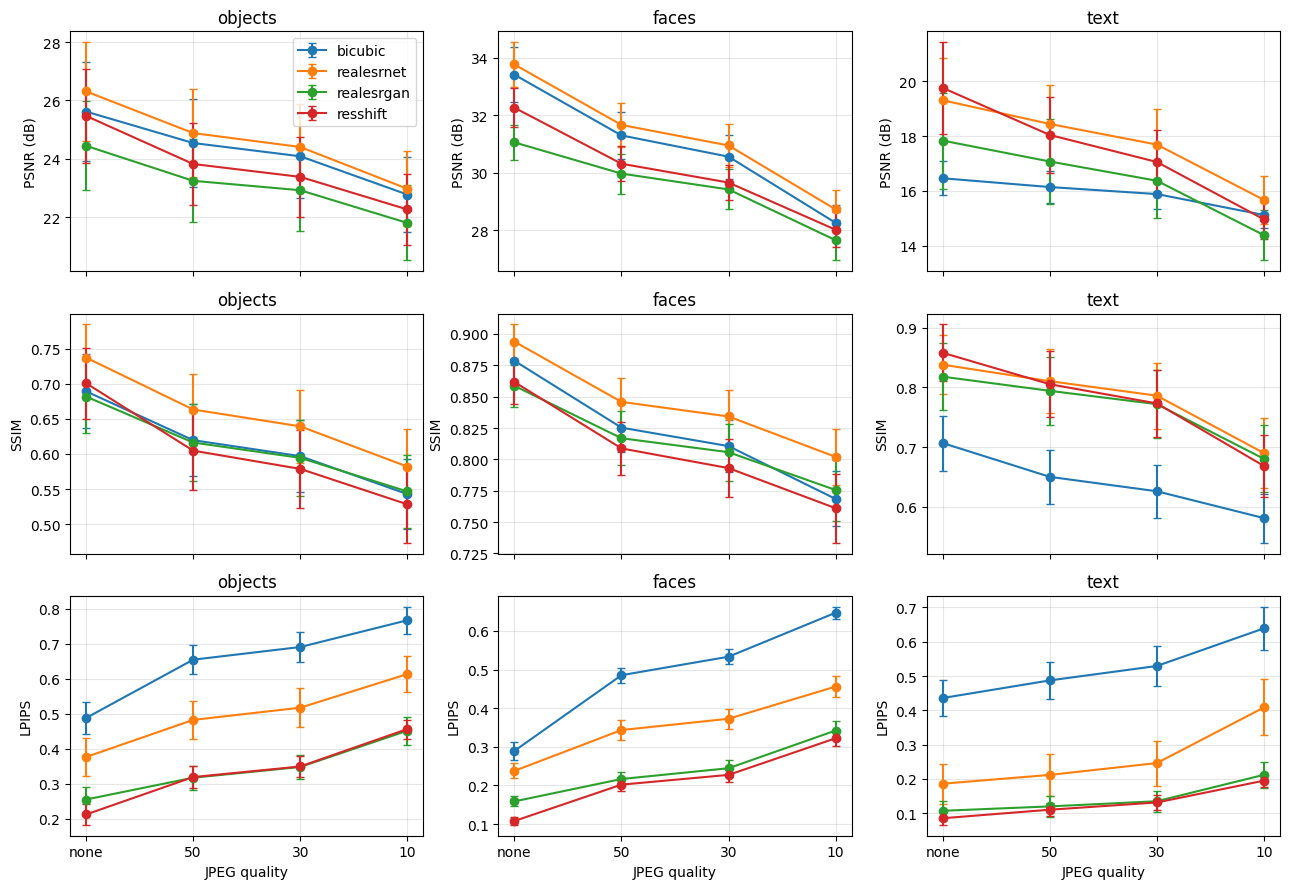

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9), sharex=True)
labels = ['PSNR (dB)', 'SSIM', 'LPIPS']
for row, metric in enumerate(['psnr', 'ssim', 'lpips']):
    for col, content in enumerate(['objects', 'faces', 'text']):
        ax = axes[row, col]
        for method in ['bicubic', 'realesrnet', 'realesrgan', 'resshift']:
            values = all_summary[(all_summary['content'] == content) & (all_summary['method'] == method)]
            values = values.set_index('jpeg').loc[qualities]
            ax.errorbar(qualities, values[metric], yerr=values[f'{metric}_ci'],
                        marker='o', capsize=3, label=method)
        ax.set_title(content)
        ax.set_ylabel(labels[row])
        ax.grid(alpha=0.3)
        if row == 2:
            ax.set_xlabel('JPEG quality')
axes[0, 0].legend()
plt.tight_layout()
fig.savefig(results / 'jpeg_sweep_dev.png', dpi=150)
plt.show()

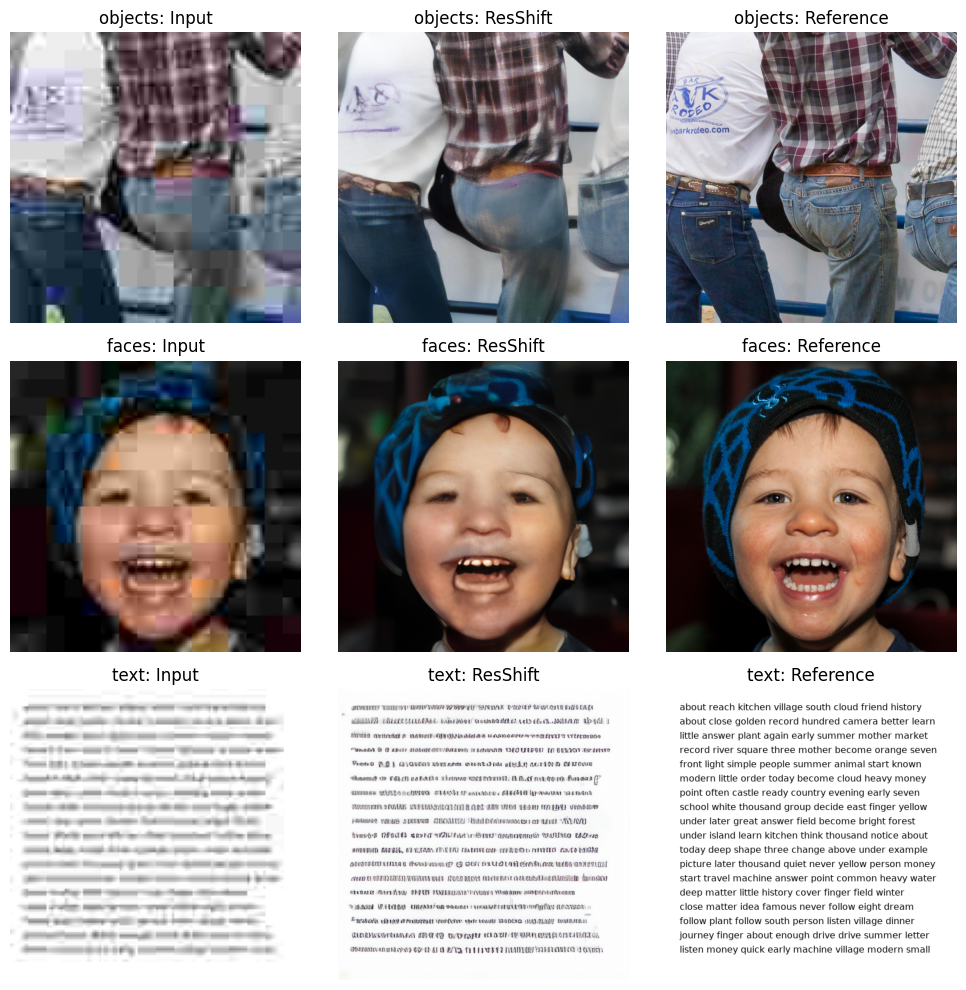

In [11]:
quality = '10'
examples = images.groupby('content', sort=False).first().reset_index()
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for row, example in enumerate(examples.itertuples()):
    name = f'{example.image_id}.png'
    paths = [data / 'lr' / f'jpeg_{quality}' / name,
             outputs / f'jpeg_{quality}' / name, data / 'hr' / name]
    for col, (path, title) in enumerate(zip(paths, ['Input', 'ResShift', 'Reference'])):
        axes[row, col].imshow(Image.open(path))
        axes[row, col].set_title(f'{example.content}: {title}')
        axes[row, col].axis('off')
plt.tight_layout()
fig.savefig(results / 'examples_dev_jpeg_10.png', dpi=150)
plt.show()

In [12]:
settings = {
    'method': 'resshift', 'version': 'v3', 'split': 'dev', 'seed': seed,
    'image_seeds': image_seeds, 'steps': 4, 'scale': 4, 'amp': True,
    'precision': 'float32 weights, float16 autocast', 'warmup_runs': 3,
    'gpu': torch.cuda.get_device_name(0), 'torch': torch.__version__,
    'cuda': torch.version.cuda, 'python': sys.version,
    'source_commit': provenance['diffusion_commit'],
    'baseline_commit': provenance['baseline_commit'], 'official_commit': revision,
    'archive_sha256': hashlib.sha256(payload).hexdigest(),
    'weights_sha256': {name: hashlib.file_digest((root / 'models' / name).open('rb'), 'sha256').hexdigest()
                       for name in weights},
    'psnr_ssim': 'BT.601 Y, 4-pixel border crop', 'lpips': 'AlexNet',
    'bootstrap_samples': evaluate.BOOTSTRAP_SAMPLES,
    'confidence': evaluate.CONFIDENCE, 'ci_format': 'bootstrap half-width'
}
(results / 'settings.json').write_text(json.dumps(settings, indent=2))
(results / 'requirements.txt').write_text(subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))
shutil.copy2(root / 'bundle_manifest.json', results / 'bundle_manifest.json')
shutil.copy2(data / 'manifest.csv', results / 'manifest.csv')
archive_path = shutil.make_archive('/content/resshift_dev_results', 'zip', results)
files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>